In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = "638377aa004b0f2632687b2afd3a7c52"

In [3]:
# Date range for fetching API s
start = '2007-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
today = dt.datetime.now().strftime('%Y-%m-%d')
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)

In [4]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [5]:
def save_figure(output_dir, today, prefix):
    # ファイル名にコードと期間を含める
    output_path = output_dir / f"{prefix}_{today}.png"
    plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
    # 保存完了のメッセージを表示
    print("saved:", output_path)

In [6]:
fred_url = "https://api.stlouisfed.org/fred/series/observations"
series_mapping = {
    #"DFF": "effective_federal_funds_rate",  # 実効FF金利
    "DFII10": "real_10y",                    # 10年TIPS実質金利
    #"FEDFUNDS": "ff_rate",                  # FF金利
    #"DFEDTARU": "maximum_interest_rate",    # 上限金利
    #"DFEDTARL": "minimum_interest_rate",    # 下限金利
    "DGS2": "us_treasury_2y",                # 2年米国債
    #"DGS5": "us_treasury_5y",               # 5年米国債
    "DGS10": "us_treasury_10y",              # 10年米国債
    #"DGS30": "us_treasury_30y",             # 30年米国債
    "M1SL": "m1_money_stock",                # M1マネーストック
    "M2SL": "m2_money_stock",                # M2マネーストック
    #"CPIAUCSL": "cpi_all_urban_consumers",  # 消費者物価指数（全都市消費者）
    #"MICH": "michigan_consumer_sentiment",  # ミシガン大学期待インフレ率
    #"DCOILWTICO": "wti",                    # 原油WTI先物価格
    #"DCOILBRENTEU": "brent",                # 原油ブレント先物価格
    #"AHETPI": "headline_inflation",         # 消費者物価指数（ヘッドラインインフレ）
    #"PPIACO": "producer_price_index",       # 生産者物価指数
    "WALCL": "federal_reserve_assets",       # 連邦準備制度の資産
    "CPIAUCSL": "cpi",                       # 消費者物価指数（全都市消費者）
}
observation_start = "2007-01-01"
observation_end = end
base_fred_params = {
    "api_key": FRED_API_KEY,
    "file_type": "json",
    "observation_start": observation_start,
    "observation_end": observation_end,
    "frequency": "m",
    "aggregation_method": "avg",
}
fred_dfs = []
for series_id, series_name in series_mapping.items():
    fred_params = base_fred_params.copy()
    fred_params["series_id"] = series_id
    fred_res = requests.get(fred_url, params=fred_params)
    fred_df = pd.DataFrame(fred_res.json()["observations"]).assign(**{
        "date": lambda df: pd.to_datetime(df["date"]),
        "value": lambda df: pd.to_numeric(df["value"], errors="coerce"),
        "interest_rate_type": series_name,
    })
    fred_dfs.append(fred_df)
    time.sleep(5)
    
us_treasury_df = pd.concat(fred_dfs)
us_treasury_df

,realtime_start,realtime_end,date,value,interest_rate_type
0,2026-10-06,2026-10-06,2007-01-01,2.440,real_10y
1,2026-10-06,2026-10-06,2007-02-01,2.360,real_10y
2,2026-10-06,2026-10-06,2007-03-01,2.180,real_10y
3,2026-10-06,2026-10-06,2007-04-01,2.260,real_10y
4,2026-10-06,2026-10-06,2007-05-01,2.370,real_10y
...,...,...,...,...,...
231,2026-10-06,2026-10-06,2026-04-01,332.407,cpi
232,2026-10-06,2026-10-06,2026-05-01,333.979,cpi
233,2026-10-06,2026-10-06,2026-06-01,332.568,cpi
234,2026-10-06,2026-10-06,2026-07-01,332.813,cpi


### 債権市場の利回りあり

In [7]:
df = (
    us_treasury_df
    .pivot(
        index="date",
        columns="interest_rate_type",
        values="value"
    )
    .sort_index()
)

df.head()

interest_rate_type,cpi,federal_reserve_assets,m1_money_stock,m2_money_stock,real_10y,us_treasury_10y,us_treasury_2y
date,,,,,,,
2007-01-01,203.437,861259.0,1371.7,7115.6,2.44,4.76,4.88
2007-02-01,204.226,867225.0,1363.0,7131.9,2.36,4.72,4.85
2007-03-01,205.288,868371.0,1366.5,7164.7,2.18,4.56,4.57
2007-04-01,205.904,867195.0,1378.0,7239.9,2.26,4.69,4.67
2007-05-01,206.755,875321.0,1380.9,7257.1,2.37,4.75,4.77


In [8]:
df["bei"] = (
    df["us_treasury_10y"]
    - df["real_10y"]
)

df["m2_yoy"] = (
    df["m2_money_stock"]
    .pct_change(12)
    * 100
)

df["walcl_yoy"] = (
    df["federal_reserve_assets"]
    .pct_change(12)
    * 100
)

df["cpi_yoy"] = (
    df["cpi"]
    .pct_change(12)
    * 100
)

In [9]:
df["bei_lag6"] = df["bei"].shift(6)

df["m2_yoy_lag12"] = df["m2_yoy"].shift(12)

df["walcl_yoy_lag12"] = (
    df["walcl_yoy"]
    .shift(12)
)

df["yc"] = (
    df["us_treasury_10y"]
    - df["us_treasury_2y"]
)


In [10]:
model_df = df[
    [
        "cpi_yoy",
        "bei_lag6",
        "m2_yoy_lag12",
        "walcl_yoy_lag12",
        "yc",
    ]
].dropna()

In [11]:
train = model_df.loc[
    :"2024-12-31"
]

test = model_df.loc[
    "2025-01-01":
]

In [12]:
X_train = train.drop(
    columns=["cpi_yoy"]
)

y_train = train["cpi_yoy"]

model = LinearRegression()

model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 2.03, 0.17, 0. ,-0.89]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['bei_lag6','m2_yoy_lag12','walcl_yoy_lag12','yc']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.915
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [13]:
X_all = model_df.drop(
    columns=["cpi_yoy"]
)

model_df["pred"] = (
    model.predict(X_all)
)

In [14]:
from sklearn.metrics import (
    mean_absolute_error,
    r2_score
)

pred_test = model.predict(
    test.drop(
        columns=["cpi_yoy"]
    )
)

mae = mean_absolute_error(
    test["cpi_yoy"],
    pred_test
)

r2 = r2_score(
    test["cpi_yoy"],
    pred_test
)

print(f"MAE : {mae:.2f}")
print(f"R2  : {r2:.3f}")

MAE : 0.41
R2  : -0.186


In [15]:
model_df["gap"] = (
    model_df["pred"]
    - model_df["cpi_yoy"]
)

In [16]:
pre2025 = model_df.loc[
    :"2024-12-31",
    "gap"
]

mu = pre2025.mean()

sigma = pre2025.std()

model_df["zscore"] = (
    model_df["gap"] - mu
) / sigma

saved: /workspace/data/figures/Official_CPI_vs_Model_Inflation_2026-10-06.png


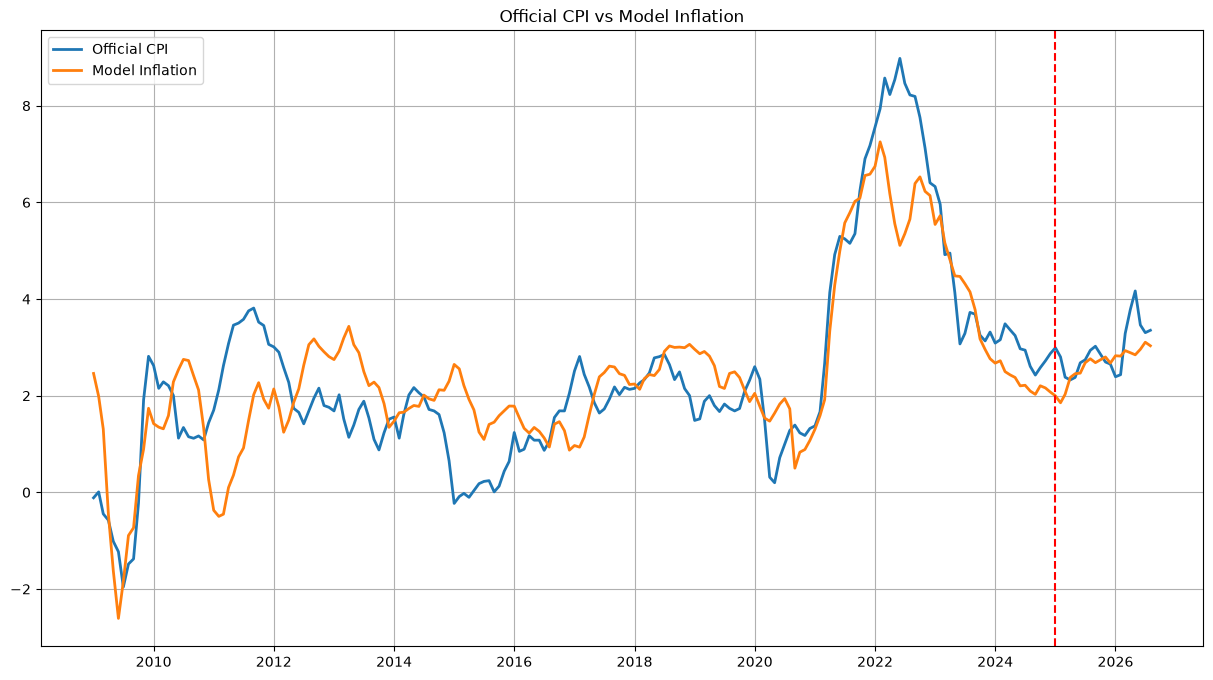

In [17]:
plt.figure(figsize=(15,8))

plt.plot(
    model_df.index,
    model_df["cpi_yoy"],
    label="Official CPI",
    linewidth=2
)

plt.plot(
    model_df.index,
    model_df["pred"],
    label="Model Inflation",
    linewidth=2
)

plt.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

plt.legend()

plt.grid(True)

plt.title(
    "Official CPI vs Model Inflation"
)

save_figure(output_dir, today, "Official_CPI_vs_Model_Inflation")

plt.show()

saved: /workspace/data/figures/Model_Inflation_Official_CPI_2026-10-06.png


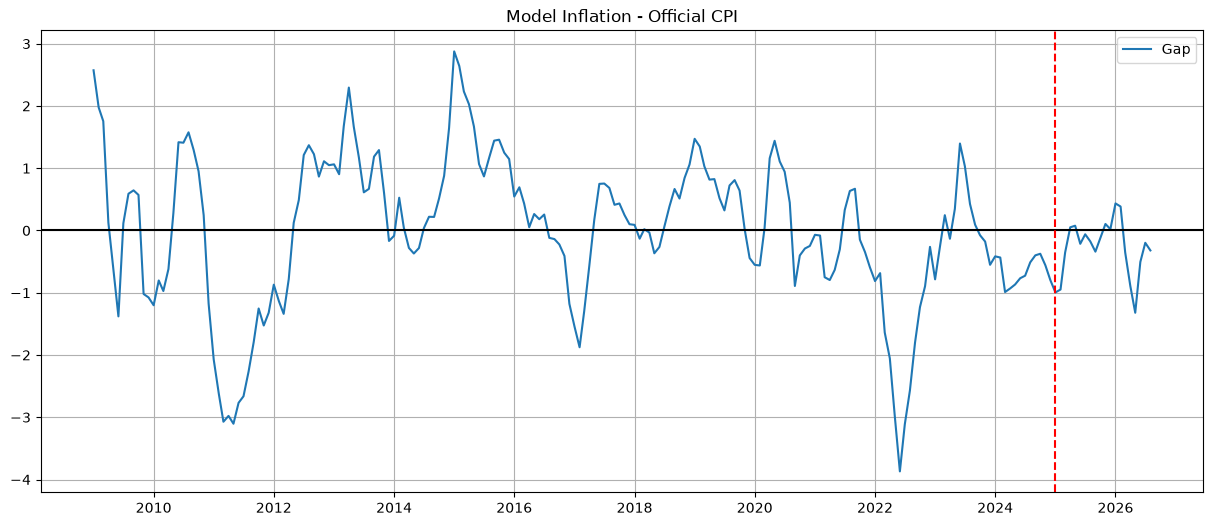

In [18]:
plt.figure(figsize=(15,6))

plt.plot(
    model_df.index,
    model_df["gap"],
    label="Gap"
)

plt.axhline(
    0,
    color="black"
)

plt.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

plt.grid(True)

plt.legend()

plt.title(
    "Model Inflation - Official CPI"
)

save_figure(output_dir, today, "Model_Inflation_Official_CPI")

plt.show()

saved: /workspace/data/figures/Gap_Z-Score_2026-10-06.png


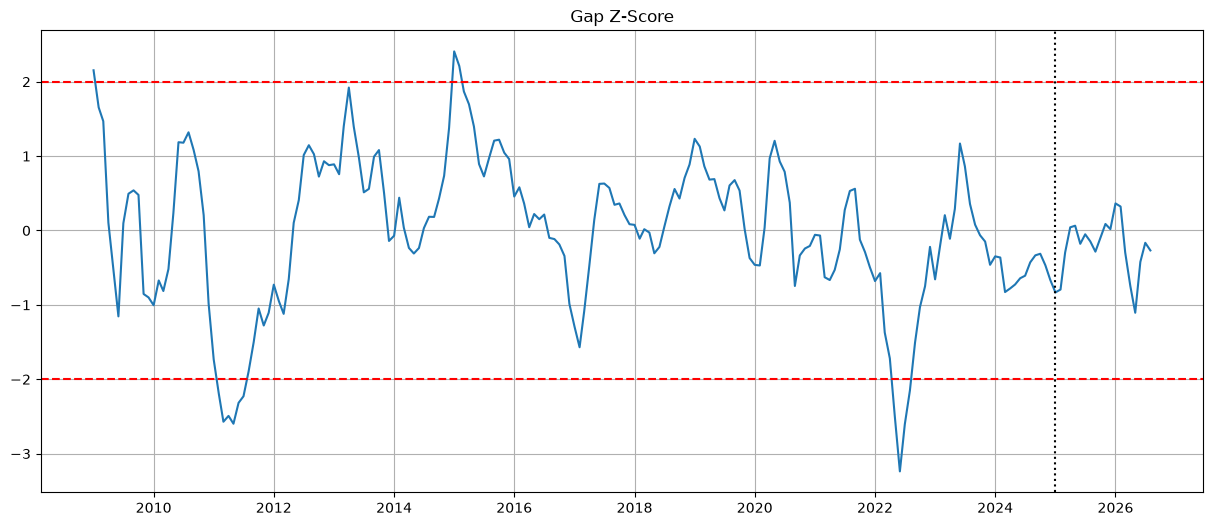

In [19]:
plt.figure(figsize=(15,6))

plt.plot(
    model_df.index,
    model_df["zscore"]
)

plt.axhline(
    2,
    color="red",
    linestyle="--"
)

plt.axhline(
    -2,
    color="red",
    linestyle="--"
)

plt.axvline(
    pd.Timestamp("2025-01-01"),
    color="black",
    linestyle=":"
)

plt.title(
    "Gap Z-Score"
)

plt.grid(True)

save_figure(output_dir, today, "Gap_Z-Score")

plt.show()

#### M1,M2,WALCLのみ

In [20]:
df = (
    us_treasury_df
    .pivot(
        index="date",
        columns="interest_rate_type",
        values="value"
    )
    .sort_index()
)

df = df.astype(float)

display(df.tail())

interest_rate_type,cpi,federal_reserve_assets,m1_money_stock,m2_money_stock,real_10y,us_treasury_10y,us_treasury_2y
date,,,,,,,
2026-06-01,332.568,6727240.0,19793.0,23114.9,2.18,4.47,4.11
2026-07-01,332.813,6737754.0,19886.5,23217.9,2.35,4.60,4.22
2026-08-01,334.131,6746283.0,19991.1,23342.8,2.40,4.68,4.22
2026-09-01,NaN,6743021.0,NaN,NaN,2.64,4.99,4.65
2026-10-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
# CPI前年比

df["cpi_yoy"] = (
    df["cpi"]
    .pct_change(12)
    * 100
)

# M1前年比

df["m1_yoy"] = (
    df["m1_money_stock"]
    .pct_change(12)
    * 100
)

# M2前年比

df["m2_yoy"] = (
    df["m2_money_stock"]
    .pct_change(12)
    * 100
)

# FRB資産前年比

df["walcl_yoy"] = (
    df["federal_reserve_assets"]
    .pct_change(12)
    * 100
)

# ラグ付与

df["m1_yoy_lag12"] = (
    df["m1_yoy"]
    .shift(12)
)

df["m2_yoy_lag12"] = (
    df["m2_yoy"]
    .shift(12)
)

df["walcl_yoy_lag12"] = (
    df["walcl_yoy"]
    .shift(12)
)

model_df = df[
    [
        "cpi_yoy",
        "m1_yoy_lag12",
        "m2_yoy_lag12",
        "walcl_yoy_lag12"
    ]
].dropna()

display(model_df.tail())

interest_rate_type,cpi_yoy,m1_yoy_lag12,m2_yoy_lag12,walcl_yoy_lag12
date,,,,
2026-04-01,3.779246,3.464197,3.891121,-9.413038
2026-05-01,4.166615,3.508597,3.874586,-8.527419
2026-06-01,3.463531,3.897270,4.137974,-7.948971
2026-07-01,3.303856,4.232675,4.392172,-7.649256
2026-08-01,3.353016,4.069244,4.249717,-7.373043


In [22]:
train = model_df.loc[
    :"2024-12-31"
]

test = model_df.loc[
    "2025-01-01":
]

X_train = train.drop(
    columns=["cpi_yoy"]
)

y_train = train["cpi_yoy"]

model = Ridge(alpha=1.0)

model.fit(
    X_train,
    y_train
)

# 全期間予測

X_all = model_df.drop(
    columns=["cpi_yoy"]
)

model_df["pred"] = (
    model.predict(X_all)
)

In [23]:
coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coef": model.coef_
})

display(
    coef_df.sort_values(
        "coef",
        ascending=False
    )
)

,feature,coef
1,m2_yoy_lag12,0.098761
0,m1_yoy_lag12,0.009319
2,walcl_yoy_lag12,-0.006814


In [24]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pred_test = model.predict(
    test.drop(
        columns=["cpi_yoy"]
    )
)

mae = mean_absolute_error(
    test["cpi_yoy"],
    pred_test
)

rmse = np.sqrt(
    mean_squared_error(
        test["cpi_yoy"],
        pred_test
    )
)

r2 = r2_score(
    test["cpi_yoy"],
    pred_test
)

print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.3f}")

MAE  : 1.057
RMSE : 1.150
R²   : -4.292


In [25]:
model_df["gap"] = (
    model_df["pred"]
    - model_df["cpi_yoy"]
)

In [26]:
pre2025 = model_df.loc[
    :"2024-12-31",
    "gap"
]

mu = pre2025.mean()

sigma = pre2025.std()

model_df["zscore"] = (
    model_df["gap"] - mu
) / sigma

saved: /workspace/data/figures/CPI_vs_Monetary_Model_2026-10-06.png


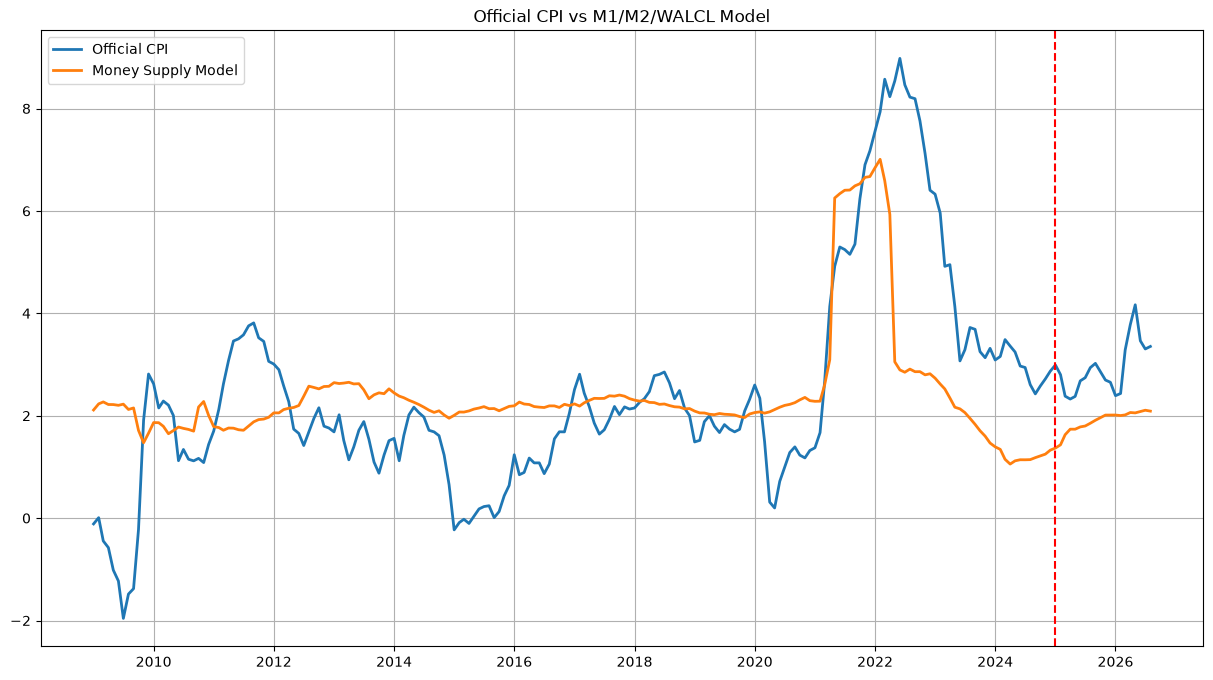

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    figsize=(15,8)
)

ax.plot(
    model_df.index,
    model_df["cpi_yoy"],
    label="Official CPI",
    linewidth=2
)

ax.plot(
    model_df.index,
    model_df["pred"],
    label="Money Supply Model",
    linewidth=2
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

ax.legend()
ax.grid(True)

ax.set_title(
    "Official CPI vs M1/M2/WALCL Model"
)

output_path = (
    output_dir
    / f"CPI_vs_Monetary_Model_{today}.png"
)

fig.savefig(
    str(output_path),
    dpi=300,
    bbox_inches="tight"
)

print("saved:", output_path)

plt.show()

saved: /workspace/data/figures/Gap_Monetary_Model_2026-10-06.png


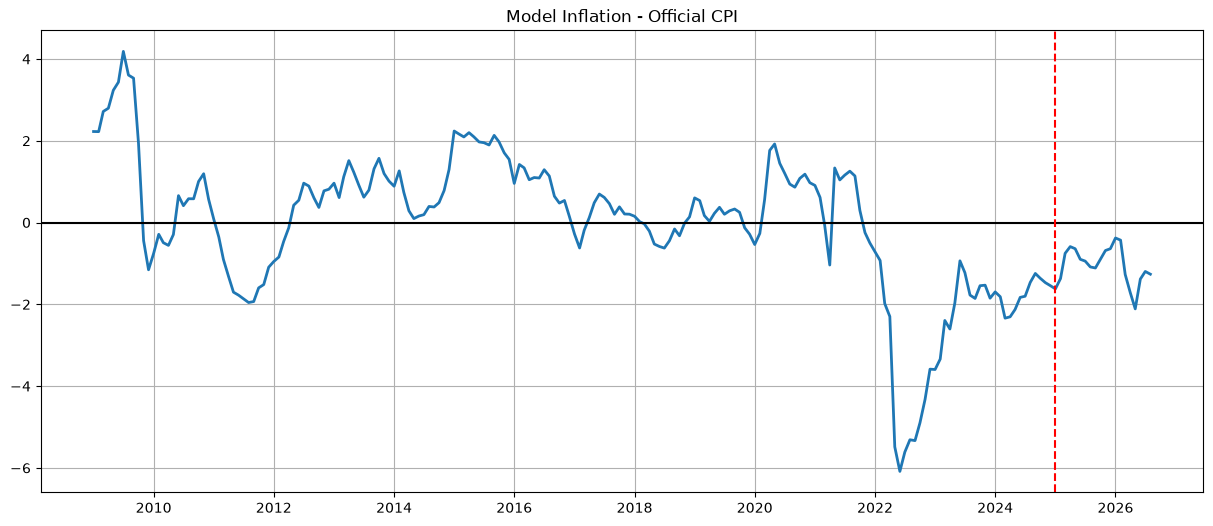

In [28]:
fig, ax = plt.subplots(
    figsize=(15,6)
)

ax.plot(
    model_df.index,
    model_df["gap"],
    linewidth=2
)

ax.axhline(
    0,
    color="black"
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

ax.grid(True)

ax.set_title(
    "Model Inflation - Official CPI"
)

output_path = (
    output_dir
    / f"Gap_Monetary_Model_{today}.png"
)

fig.savefig(
    str(output_path),
    dpi=300,
    bbox_inches="tight"
)

print("saved:", output_path)

plt.show()

saved: /workspace/data/figures/Gap_ZScore_2026-10-06.png


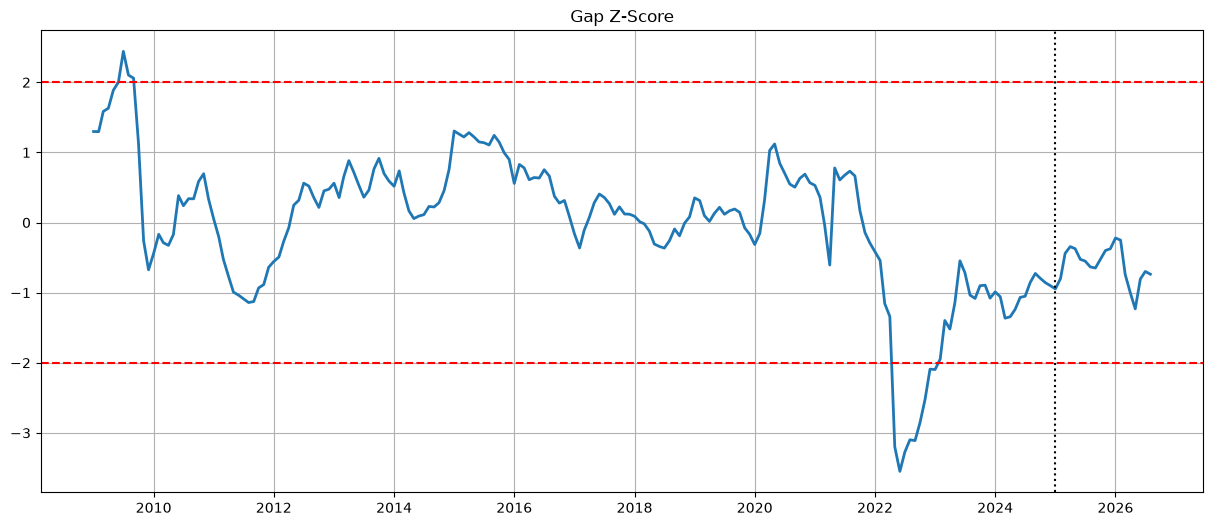

In [29]:
fig, ax = plt.subplots(
    figsize=(15,6)
)

ax.plot(
    model_df.index,
    model_df["zscore"],
    linewidth=2
)

ax.axhline(
    2,
    color="red",
    linestyle="--"
)

ax.axhline(
    -2,
    color="red",
    linestyle="--"
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="black",
    linestyle=":"
)

ax.grid(True)

ax.set_title(
    "Gap Z-Score"
)

output_path = (
    output_dir
    / f"Gap_ZScore_{today}.png"
)

fig.savefig(
    str(output_path),
    dpi=300,
    bbox_inches="tight"
)

print("saved:", output_path)

plt.show()

#### 貨幣圧力指数

In [30]:
df["cpi_yoy"] = (
    df["cpi"]
    .pct_change(12)
    * 100
)

df["m1_yoy"] = (
    df["m1_money_stock"]
    .pct_change(12)
    * 100
)

df["m2_yoy"] = (
    df["m2_money_stock"]
    .pct_change(12)
    * 100
)

df["walcl_yoy"] = (
    df["federal_reserve_assets"]
    .pct_change(12)
    * 100
)

# 貨幣供給は遅れて効く

df["m1_yoy_lag12"] = (
    df["m1_yoy"]
    .shift(12)
)

df["m2_yoy_lag12"] = (
    df["m2_yoy"]
    .shift(12)
)

df["walcl_yoy_lag12"] = (
    df["walcl_yoy"]
    .shift(12)
)


In [31]:
for col in [
    "m1_yoy_lag12",
    "m2_yoy_lag12",
    "walcl_yoy_lag12",
]:
    df[f"{col}_z"] = (
        df[col] - df[col].mean()
    ) / df[col].std()

In [32]:
df["mpi"] = (
      0.2 * df["m1_yoy_lag12_z"]
    + 0.4 * df["m2_yoy_lag12_z"]
    + 0.4 * df["walcl_yoy_lag12_z"]
)

In [33]:
df["cpi_z"] = (
    df["cpi_yoy"]
    - df["cpi_yoy"].mean()
) / df["cpi_yoy"].std()


In [34]:
compare_df = df[
    [
        "cpi_yoy",
        "cpi_z",
        "mpi",
    ]
].dropna()

compare_df.tail()


interest_rate_type,cpi_yoy,cpi_z,mpi
date,,,
2026-04-01,3.779246,0.635486,-0.542353
2026-05-01,4.166615,0.831647,-0.533078
2026-06-01,3.463531,0.475609,-0.505948
2026-07-01,3.303856,0.394751,-0.482898
2026-08-01,3.353016,0.419646,-0.490549


saved: /workspace/data/figures/Monetary_Pressure_Index_2026-10-06.png


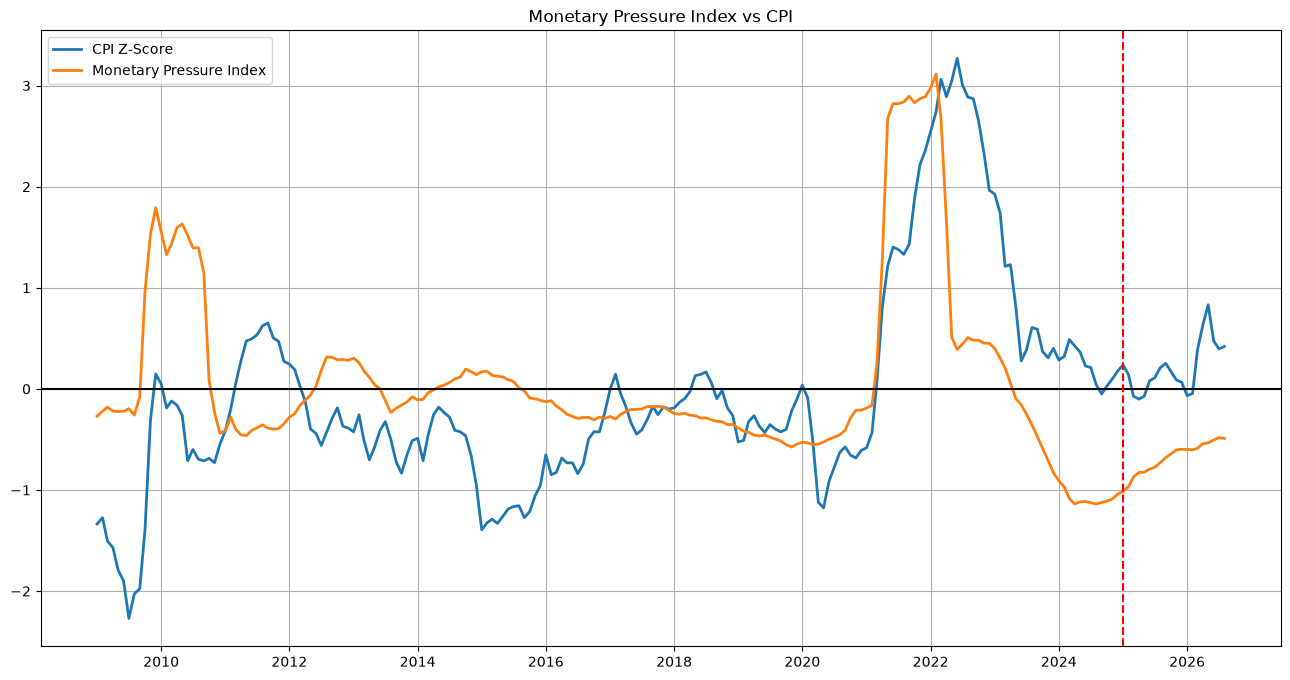

In [35]:

fig, ax = plt.subplots(
    figsize=(16,8)
)

ax.plot(
    compare_df.index,
    compare_df["cpi_z"],
    label="CPI Z-Score",
    linewidth=2,
)

ax.plot(
    compare_df.index,
    compare_df["mpi"],
    label="Monetary Pressure Index",
    linewidth=2,
)

ax.axhline(
    0,
    color="black"
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

ax.legend()

ax.grid(True)

ax.set_title(
    "Monetary Pressure Index vs CPI"
)

output_path = (
    output_dir
    / f"Monetary_Pressure_Index_{today}.png"
)

fig.savefig(
    str(output_path),
    dpi=300,
    bbox_inches="tight"
)

print("saved:", output_path)

plt.show()

In [36]:
compare_df["gap"] = (
    compare_df["mpi"]
    - compare_df["cpi_z"]
)

saved: /workspace/data/figures/Monetary_Pressure_Gap_2026-10-06.png


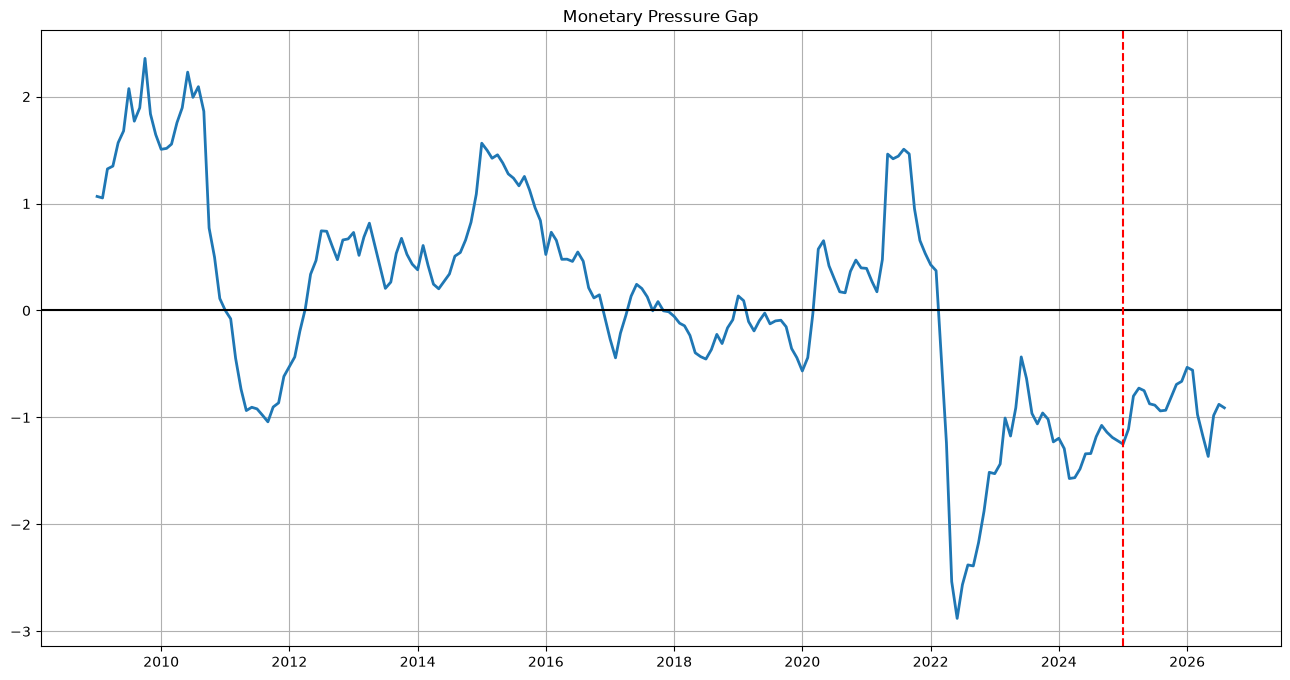

In [37]:
fig, ax = plt.subplots(
    figsize=(16,8)
)

ax.plot(
    compare_df.index,
    compare_df["gap"],
    linewidth=2
)

ax.axhline(
    0,
    color="black"
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

ax.grid(True)

ax.set_title(
    "Monetary Pressure Gap"
)

output_path = (
    output_dir
    / f"Monetary_Pressure_Gap_{today}.png"
)

fig.savefig(
    str(output_path),
    dpi=300,
    bbox_inches="tight"
)

print("saved:", output_path)

plt.show()

In [38]:
compare_df["cum_gap"] = (
    compare_df["gap"]
    .cumsum()
)

saved: /workspace/data/figures/Cumulative_Monetary_Gap_2026-10-06.png


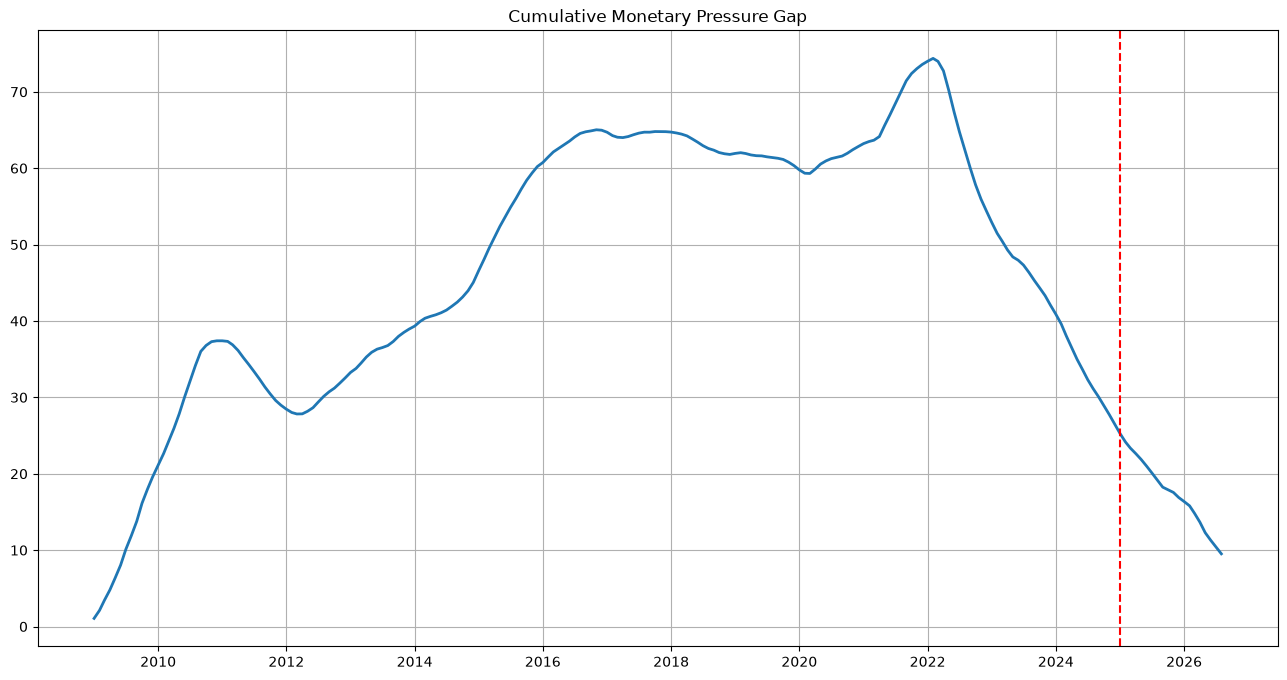

In [39]:
fig, ax = plt.subplots(
    figsize=(16,8)
)

ax.plot(
    compare_df.index,
    compare_df["cum_gap"],
    linewidth=2
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

ax.grid(True)

ax.set_title(
    "Cumulative Monetary Pressure Gap"
)

output_path = (
    output_dir
    / f"Cumulative_Monetary_Gap_{today}.png"
)

fig.savefig(
    str(output_path),
    dpi=300,
    bbox_inches="tight"
)

print("saved:", output_path)

plt.show()

#### M1除外、M2V追加

In [40]:
m2v_params = {
    "api_key": FRED_API_KEY,
    "file_type": "json",
    "series_id": "M2V",
    "observation_start": observation_start,
    "observation_end": observation_end,
}

m2v_res = requests.get(
    fred_url,
    params=m2v_params,
)

m2v_df = (
    pd.DataFrame(
        m2v_res.json()["observations"]
    )
    .assign(
        date=lambda x: pd.to_datetime(
            x["date"]
        ),
        value=lambda x: pd.to_numeric(
            x["value"],
            errors="coerce"
        ),
    )
)

m2v_df = m2v_df[
    ["date", "value"]
].rename(
    columns={
        "value": "m2_velocity"
    }
)

m2v_df.tail()

,date,m2_velocity
73,2025-04-01,1.402
74,2025-07-01,1.411
75,2025-10-01,1.411
76,2026-01-01,1.415
77,2026-04-01,1.418


In [41]:
df = (
    us_treasury_df
    .pivot(
        index="date",
        columns="interest_rate_type",
        values="value"
    )
    .sort_index()
)

df = df.astype(float)

df.head()

interest_rate_type,cpi,federal_reserve_assets,m1_money_stock,m2_money_stock,real_10y,us_treasury_10y,us_treasury_2y
date,,,,,,,
2007-01-01,203.437,861259.0,1371.7,7115.6,2.44,4.76,4.88
2007-02-01,204.226,867225.0,1363.0,7131.9,2.36,4.72,4.85
2007-03-01,205.288,868371.0,1366.5,7164.7,2.18,4.56,4.57
2007-04-01,205.904,867195.0,1378.0,7239.9,2.26,4.69,4.67
2007-05-01,206.755,875321.0,1380.9,7257.1,2.37,4.75,4.77


In [42]:
monthly_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="MS",
)

m2v_monthly = (
    m2v_df
    .set_index("date")
    .reindex(monthly_index)
    .ffill()
)

m2v_monthly.index.name = "date"

m2v_monthly.head()

,m2_velocity
date,
2007-01-01,1.992
2007-02-01,1.992
2007-03-01,1.992
2007-04-01,1.983
2007-05-01,1.983


In [43]:
df = df.merge(
    m2v_monthly,
    left_index=True,
    right_index=True,
    how="left"
)

df["m2_velocity"] = (
    df["m2_velocity"]
    .ffill()
)

df.tail()

,cpi,federal_reserve_assets,m1_money_stock,m2_money_stock,real_10y,us_treasury_10y,us_treasury_2y,m2_velocity
date,,,,,,,,
2026-06-01,332.568,6727240.0,19793.0,23114.9,2.18,4.47,4.11,1.418
2026-07-01,332.813,6737754.0,19886.5,23217.9,2.35,4.60,4.22,1.418
2026-08-01,334.131,6746283.0,19991.1,23342.8,2.40,4.68,4.22,1.418
2026-09-01,NaN,6743021.0,NaN,NaN,2.64,4.99,4.65,1.418
2026-10-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.418


In [44]:
df["cpi_yoy"] = (
    df["cpi"]
    .pct_change(12)
    * 100
)

In [45]:
df["m2_yoy"] = (
    df["m2_money_stock"]
    .pct_change(12)
    * 100
)

In [46]:
df["walcl_yoy"] = (
    df["federal_reserve_assets"]
    .pct_change(12)
    * 100
)

In [47]:
df["m2v_yoy"] = (
    df["m2_velocity"]
    .pct_change(12)
    * 100
)

In [48]:
df["m2_yoy_lag12"] = (
    df["m2_yoy"]
    .shift(12)
)

df["walcl_yoy_lag12"] = (
    df["walcl_yoy"]
    .shift(12)
)

df["m2v_yoy_lag12"] = (
    df["m2v_yoy"]
    .shift(12)
)

In [49]:
features = [
    "m2_yoy_lag12",
    "walcl_yoy_lag12",
    "m2v_yoy_lag12",
]

for col in features:

    df[f"{col}_z"] = (
        df[col]
        - df[col].mean()
    ) / df[col].std()

In [50]:
df["mpi_v2"] = (
      0.4 * df["m2_yoy_lag12_z"]
    + 0.3 * df["walcl_yoy_lag12_z"]
    + 0.3 * df["m2v_yoy_lag12_z"]
)

In [51]:
df["cpi_z"] = (
    df["cpi_yoy"]
    - df["cpi_yoy"].mean()
) / df["cpi_yoy"].std()

In [52]:
compare_df = df[
    [
        "cpi_z",
        "mpi_v2",
    ]
].dropna()

In [53]:
compare_df["gap_v2"] = (
    compare_df["mpi_v2"]
    - compare_df["cpi_z"]
)

In [54]:
compare_df["cum_gap_v2"] = (
    compare_df["gap_v2"]
    .cumsum()
)

In [55]:
corr = compare_df[
    ["mpi_v2", "cpi_z"]
].corr().iloc[0, 1]

print(
    f"MPI v2 vs CPI correlation : {corr:.4f}"
)

MPI v2 vs CPI correlation : 0.5338


In [56]:
results = []

for lag in range(-24, 25):

    corr = compare_df["mpi_v2"].corr(
        compare_df["cpi_z"].shift(lag)
    )

    results.append(
        [lag, corr]
    )

lag_df = pd.DataFrame(
    results,
    columns=[
        "lag",
        "corr"
    ]
)

display(
    lag_df.sort_values(
        "corr",
        ascending=False
    ).head(10)
)

,lag,corr
23,-1,0.546915
22,-2,0.540565
24,0,0.533826
21,-3,0.530063
20,-4,0.524402
19,-5,0.518006
18,-6,0.507218
25,1,0.504324
17,-7,0.494646
16,-8,0.480636


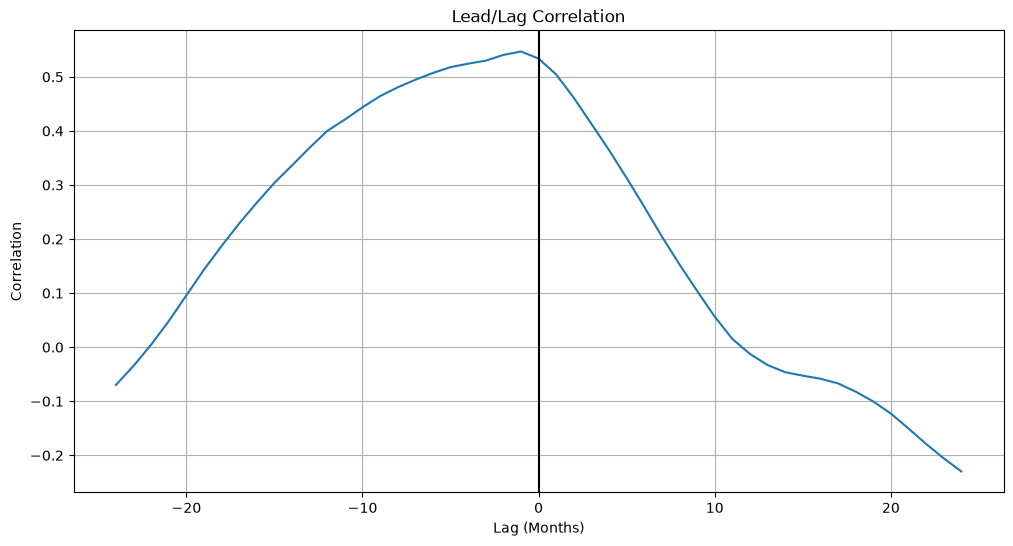

In [57]:
fig, ax = plt.subplots(
    figsize=(12,6)
)

ax.plot(
    lag_df["lag"],
    lag_df["corr"]
)

ax.axvline(
    0,
    color="black"
)

ax.grid(True)

ax.set_title(
    "Lead/Lag Correlation"
)

ax.set_xlabel(
    "Lag (Months)"
)

ax.set_ylabel(
    "Correlation"
)

plt.show()

saved: /workspace/data/figures/MPI_v2_vs_CPI_2026-10-06.png


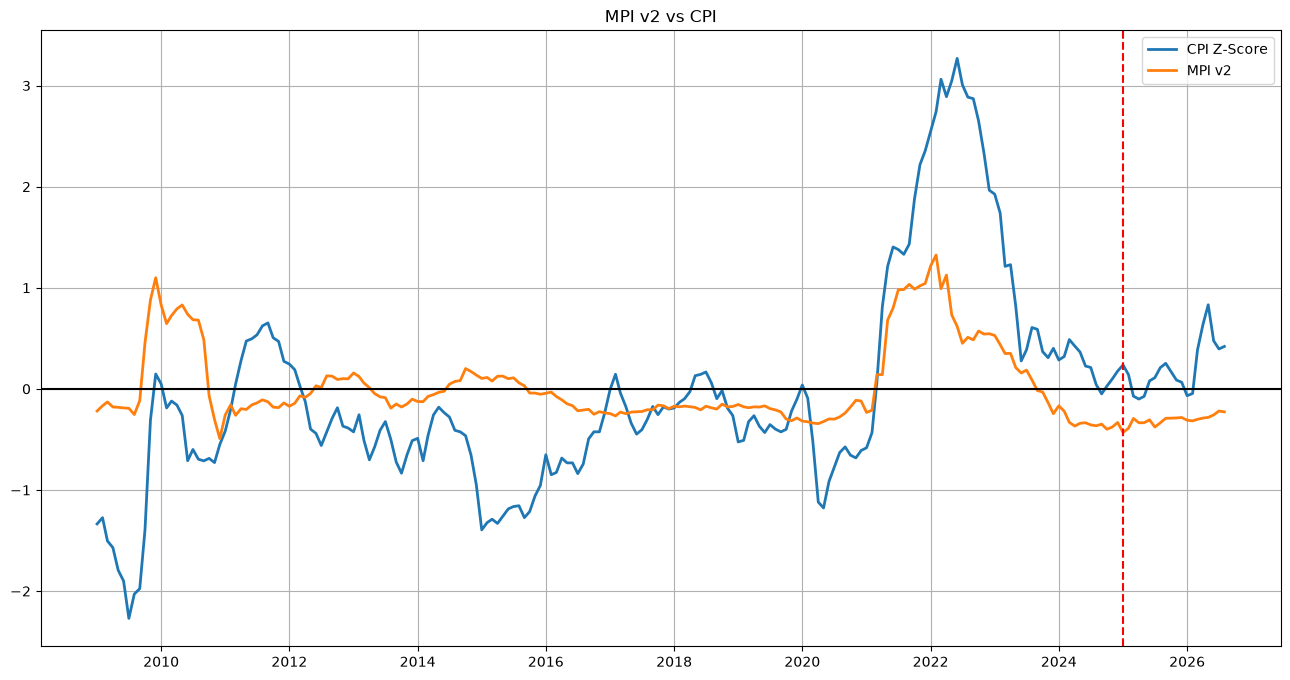

In [58]:
fig, ax = plt.subplots(
    figsize=(16,8)
)

ax.plot(
    compare_df.index,
    compare_df["cpi_z"],
    label="CPI Z-Score",
    linewidth=2
)

ax.plot(
    compare_df.index,
    compare_df["mpi_v2"],
    label="MPI v2",
    linewidth=2
)

ax.axhline(
    0,
    color="black"
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

ax.legend()

ax.grid(True)

ax.set_title(
    "MPI v2 vs CPI"
)

output_path = (
    output_dir
    / f"MPI_v2_vs_CPI_{today}.png"
)

fig.savefig(
    str(output_path),
    dpi=300,
    bbox_inches="tight"
)

print("saved:", output_path)

plt.show()

saved: /workspace/data/figures/MPI_v2_Gap_2026-10-06.png


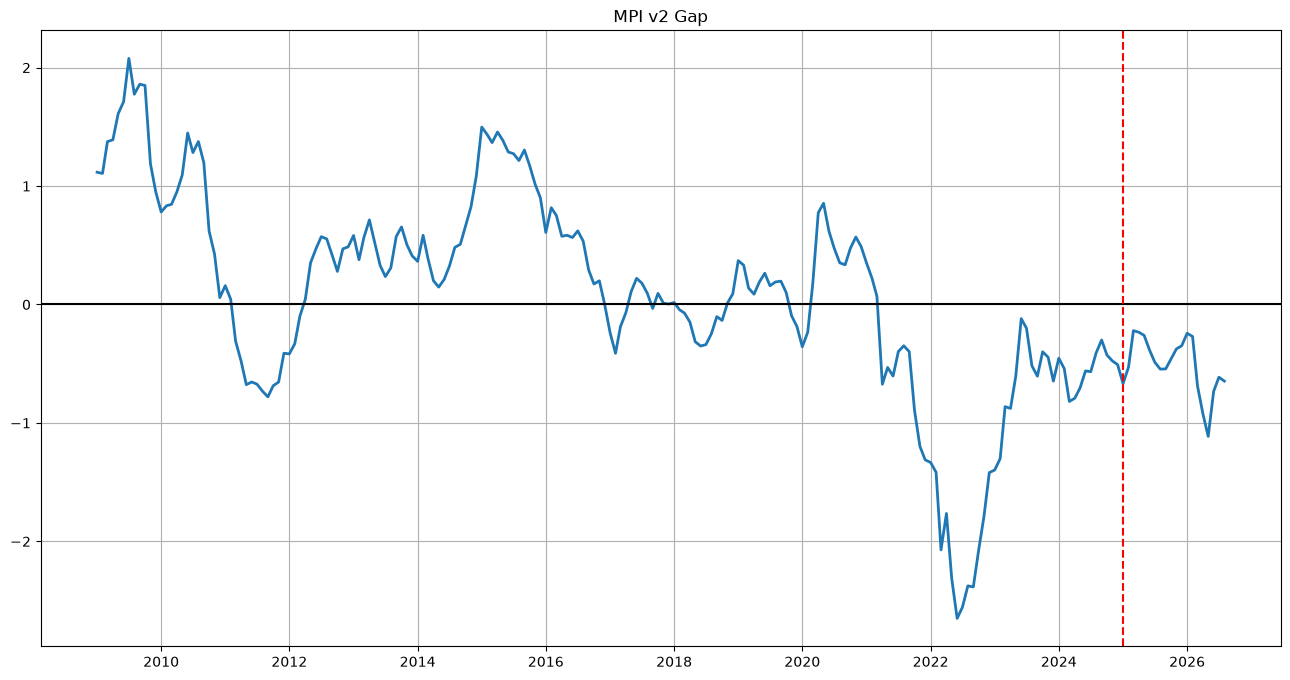

In [59]:
compare_df["gap_v2"] = (
    compare_df["mpi_v2"]
    - compare_df["cpi_z"]
)

fig, ax = plt.subplots(
    figsize=(16,8)
)

ax.plot(
    compare_df.index,
    compare_df["gap_v2"],
    linewidth=2
)

ax.axhline(
    0,
    color="black"
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

ax.grid(True)

ax.set_title(
    "MPI v2 Gap"
)

output_path = (
    output_dir
    / f"MPI_v2_Gap_{today}.png"
)

fig.savefig(
    str(output_path),
    dpi=300,
    bbox_inches="tight"
)

print("saved:", output_path)

plt.show()


saved: /workspace/data/figures/MPI_v2_CumulativeGap_2026-10-06.png


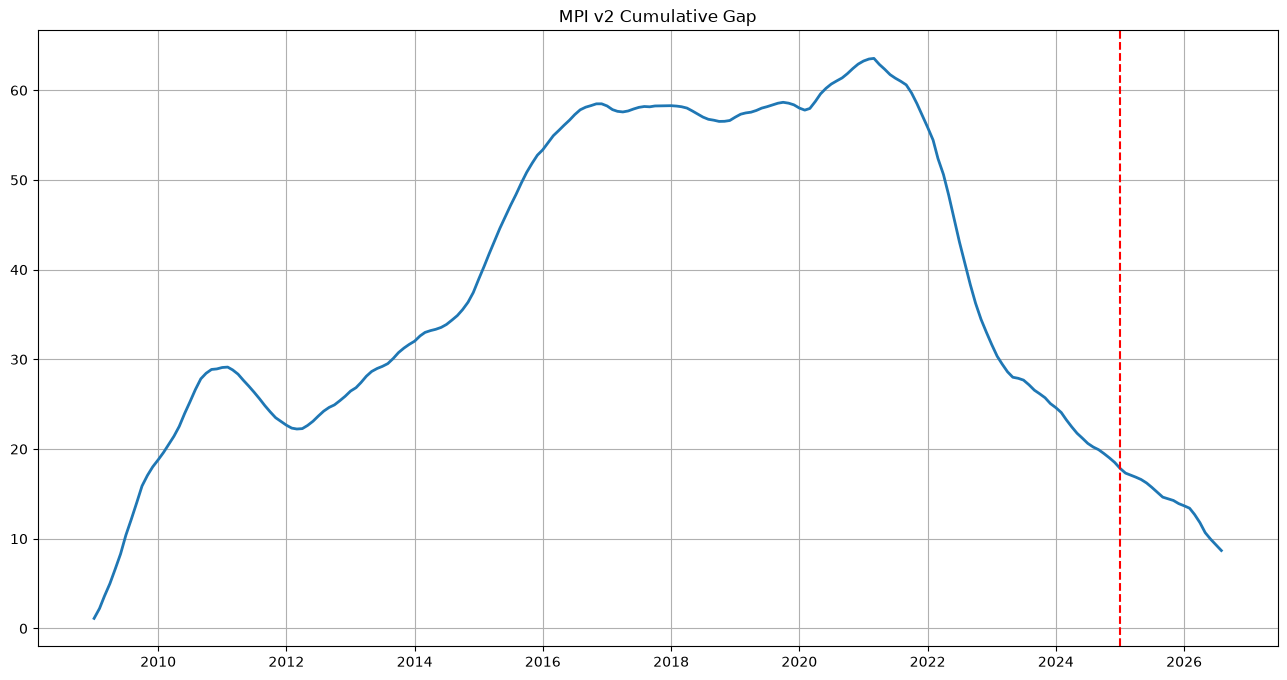

In [60]:
compare_df["cum_gap_v2"] = (
    compare_df["gap_v2"]
    .cumsum()
)

fig, ax = plt.subplots(
    figsize=(16,8)
)

ax.plot(
    compare_df.index,
    compare_df["cum_gap_v2"],
    linewidth=2
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

ax.grid(True)

ax.set_title(
    "MPI v2 Cumulative Gap"
)

output_path = (
    output_dir
    / f"MPI_v2_CumulativeGap_{today}.png"
)

fig.savefig(
    str(output_path),
    dpi=300,
    bbox_inches="tight"
)

print("saved:", output_path)

plt.show()

In [61]:
df["mpi_v1"] = (
      0.5 * df["m2_yoy_lag12_z"]
    + 0.5 * df["walcl_yoy_lag12_z"]
)

In [62]:
comparison = pd.DataFrame({
    "cpi_z": compare_df["cpi_z"],
    "mpi_v1": df.loc[
        compare_df.index,
        "mpi_v1"
    ],
    "mpi_v2": df.loc[
        compare_df.index,
        "mpi_v2"
    ]
})

print(
    "MPI v1 correlation:",
    comparison["mpi_v1"].corr(
        comparison["cpi_z"]
    )
)

print(
    "MPI v2 correlation:",
    comparison["mpi_v2"].corr(
        comparison["cpi_z"]
    )
)

MPI v1 correlation: 0.3573290124635669
MPI v2 correlation: 0.5338260580208181


#### M2・WALCL・M2Vの最適ラグ探索

In [63]:
lags = [3,6,9,12,15,18,21,24]

results = []

for lag in lags:

    m2_lag = (
        df["m2_yoy"]
        .shift(lag)
    )

    walcl_lag = (
        df["walcl_yoy"]
        .shift(lag)
    )

    m2v_lag = (
        df["m2v_yoy"]
        .shift(lag)
    )

    temp = pd.DataFrame({
        "m2": m2_lag,
        "walcl": walcl_lag,
        "m2v": m2v_lag,
        "cpi": df["cpi_yoy"],
    })

    temp = temp.dropna()

    for col in ["m2", "walcl", "m2v"]:
        temp[col] = (
            temp[col] - temp[col].mean()
        ) / temp[col].std()

    temp["mpi"] = (
        temp["m2"]
        + temp["walcl"]
        + temp["m2v"]
    ) / 3

    corr = temp["mpi"].corr(
        (
            temp["cpi"]
            - temp["cpi"].mean()
        )
        / temp["cpi"].std()
    )

    results.append(
        [lag, corr]
    )

lag_search_df = pd.DataFrame(
    results,
    columns=[
        "lag",
        "corr"
    ]
)

display(
    lag_search_df.sort_values(
        "corr",
        ascending=False
    )
)


,lag,corr
3,12,0.515815
4,15,0.489975
5,18,0.443734
2,9,0.400197
6,21,0.391706
7,24,0.334429
1,6,0.239847
0,3,0.093887


saved: /workspace/data/figures/MPI_Correlation_by_Lag_2026-10-06.png


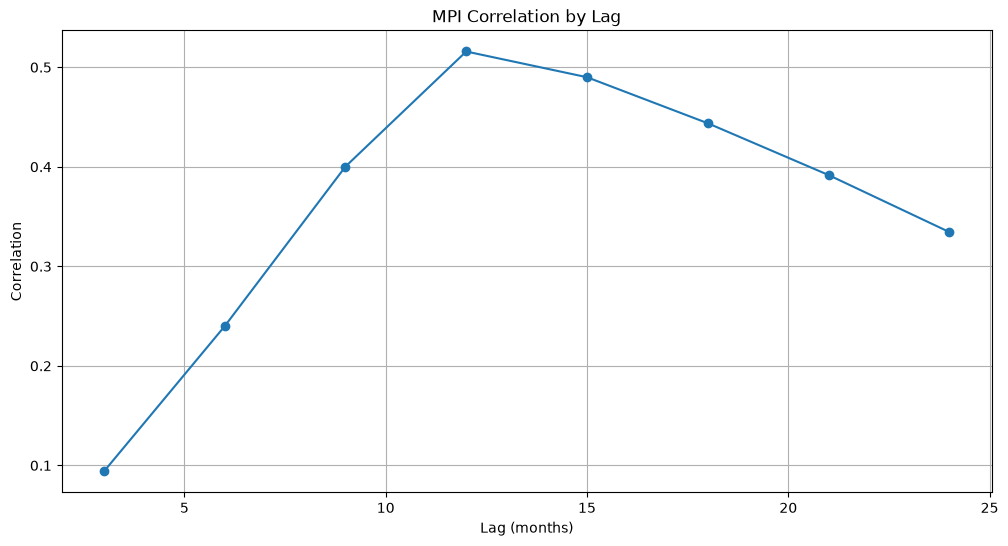

In [64]:
fig, ax = plt.subplots(
    figsize=(12,6)
)

ax.plot(
    lag_search_df["lag"],
    lag_search_df["corr"],
    marker="o"
)

ax.grid(True)

ax.set_title(
    "MPI Correlation by Lag"
)

ax.set_xlabel(
    "Lag (months)"
)

ax.set_ylabel(
    "Correlation"
)

output_path = (
    output_dir
    / f"MPI_Correlation_by_Lag_{today}.png"
)

fig.savefig(
    str(output_path),
    dpi=300,
    bbox_inches="tight"
)

print("saved:", output_path)

plt.show()

In [65]:
from itertools import product

results = []

for m2_lag in range(3, 25, 3):

    for walcl_lag in range(3, 25, 3):

        for m2v_lag in range(3, 25, 3):

            tmp = pd.DataFrame()

            tmp["cpi"] = df["cpi_yoy"]

            tmp["m2"] = (
                df["m2_yoy"]
                .shift(m2_lag)
            )

            tmp["walcl"] = (
                df["walcl_yoy"]
                .shift(walcl_lag)
            )

            tmp["m2v"] = (
                df["m2v_yoy"]
                .shift(m2v_lag)
            )

            tmp = tmp.dropna()

            for col in [
                "m2",
                "walcl",
                "m2v",
            ]:
                tmp[col] = (
                    tmp[col]
                    - tmp[col].mean()
                ) / tmp[col].std()

            tmp["mpi"] = (
                tmp["m2"]
                + tmp["walcl"]
                + tmp["m2v"]
            ) / 3

            cpi_z = (
                tmp["cpi"]
                - tmp["cpi"].mean()
            ) / tmp["cpi"].std()

            corr = (
                tmp["mpi"]
                .corr(cpi_z)
            )

            results.append([
                m2_lag,
                walcl_lag,
                m2v_lag,
                corr
            ])

search_df = pd.DataFrame(
    results,
    columns=[
        "m2_lag",
        "walcl_lag",
        "m2v_lag",
        "corr"
    ]
)

display(
    search_df
    .sort_values(
        "corr",
        ascending=False
    )
    .head(20)
)

,m2_lag,walcl_lag,m2v_lag,corr
248,12,24,3,0.608603
184,9,24,3,0.608288
249,12,24,6,0.574917
120,6,24,3,0.572787
312,15,24,3,0.571529
384,21,3,3,0.568863
176,9,21,3,0.567514
185,9,24,6,0.567060
240,12,21,3,0.563627
392,21,6,3,0.556835


#### lagを固定しmpi_v3を再構築

In [66]:
# ====================
# MPI v3
# 最適ラグ版
# ====================

df["m2_yoy_lag12"] = (
    df["m2_yoy"]
    .shift(12)
)

df["walcl_yoy_lag24"] = (
    df["walcl_yoy"]
    .shift(24)
)

df["m2v_yoy_lag3"] = (
    df["m2v_yoy"]
    .shift(3)
)

cols = [
    "m2_yoy_lag12",
    "walcl_yoy_lag24",
    "m2v_yoy_lag3",
]

for col in cols:

    df[f"{col}_z"] = (
        df[col]
        - df[col].mean()
    ) / df[col].std()

df["mpi_v3"] = (
      df["m2_yoy_lag12_z"]
    + df["walcl_yoy_lag24_z"]
    + df["m2v_yoy_lag3_z"]
) / 3

In [67]:
df["cpi_z"] = (
    df["cpi_yoy"]
    - df["cpi_yoy"].mean()
) / df["cpi_yoy"].std()

In [68]:
compare_v3 = df[
    [
        "cpi_yoy",
        "cpi_z",
        "mpi_v3",
    ]
].dropna()

In [69]:
compare_v3["gap_v3"] = (
    compare_v3["mpi_v3"]
    - compare_v3["cpi_z"]
)

compare_v3["cum_gap_v3"] = (
    compare_v3["gap_v3"]
    .cumsum()
)

In [70]:
corr_v3 = (
    compare_v3["mpi_v3"]
    .corr(
        compare_v3["cpi_z"]
    )
)

print(
    f"MPI v3 correlation = {corr_v3:.4f}"
)

MPI v3 correlation = 0.6132


In [71]:
result_path = (
    output_dir
    / f"MPI_v3_results_{today}.csv"
)

compare_v3.to_csv(
    result_path
)

print(
    "saved:",
    result_path
)

saved: /workspace/data/figures/MPI_v3_results_2026-10-06.csv


In [72]:
comparison_df = pd.DataFrame({
    "cpi_z": compare_v3["cpi_z"],
    "mpi_v2": df.loc[
        compare_v3.index,
        "mpi_v2"
    ],
    "mpi_v3": compare_v3["mpi_v3"]
})

corr_v2 = (
    comparison_df["mpi_v2"]
    .corr(
        comparison_df["cpi_z"]
    )
)

corr_v3 = (
    comparison_df["mpi_v3"]
    .corr(
        comparison_df["cpi_z"]
    )
)

summary = pd.DataFrame({
    "model": [
        "MPI_v2",
        "MPI_v3",
    ],
    "correlation": [
        corr_v2,
        corr_v3,
    ]
})

print(summary)

summary_path = (
    output_dir
    / f"MPI_comparison_{today}.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

print(
    "saved:",
    summary_path
)

    model  correlation
0  MPI_v2     0.572437
1  MPI_v3     0.613197
saved: /workspace/data/figures/MPI_comparison_2026-10-06.csv


saved: /workspace/data/figures/MPI_v3_vs_CPI_2026-10-06.png


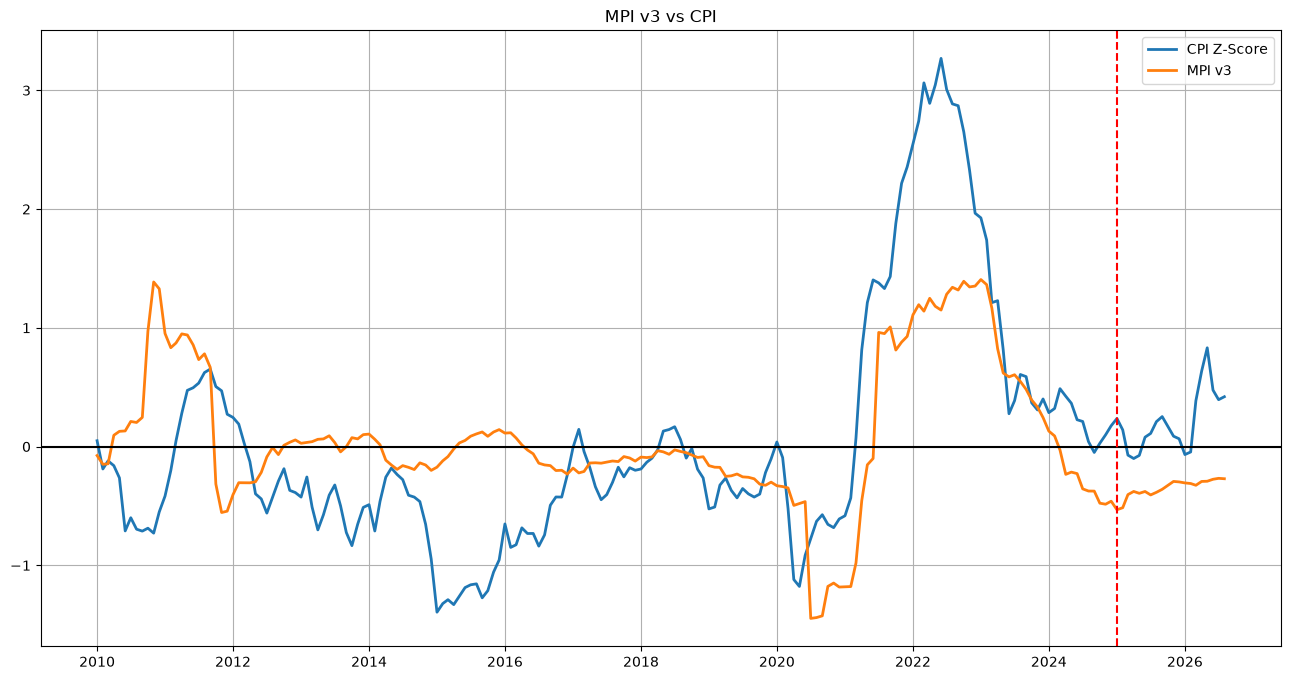

In [73]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    figsize=(16,8)
)

ax.plot(
    compare_v3.index,
    compare_v3["cpi_z"],
    label="CPI Z-Score",
    linewidth=2
)

ax.plot(
    compare_v3.index,
    compare_v3["mpi_v3"],
    label="MPI v3",
    linewidth=2
)

ax.axhline(
    0,
    color="black"
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

ax.legend()

ax.grid(True)

ax.set_title(
    "MPI v3 vs CPI"
)

output_path = (
    output_dir
    / f"MPI_v3_vs_CPI_{today}.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print(
    "saved:",
    output_path
)

plt.show()

saved: /workspace/data/figures/MPI_v3_Gap_2026-10-06.png


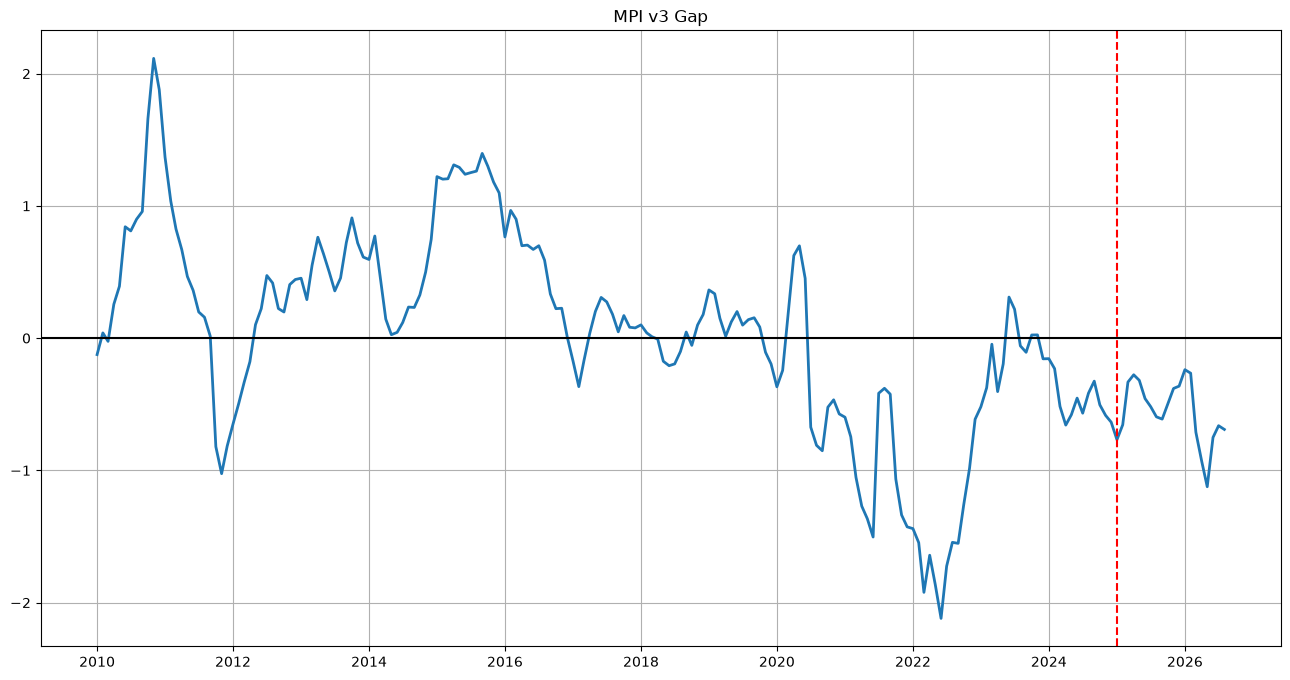

In [74]:
fig, ax = plt.subplots(
    figsize=(16,8)
)

ax.plot(
    compare_v3.index,
    compare_v3["gap_v3"],
    linewidth=2
)

ax.axhline(
    0,
    color="black"
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

ax.grid(True)

ax.set_title(
    "MPI v3 Gap"
)

output_path = (
    output_dir
    / f"MPI_v3_Gap_{today}.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print(
    "saved:",
    output_path
)

plt.show()

saved: /workspace/data/figures/MPI_v3_CumulativeGap_2026-10-06.png


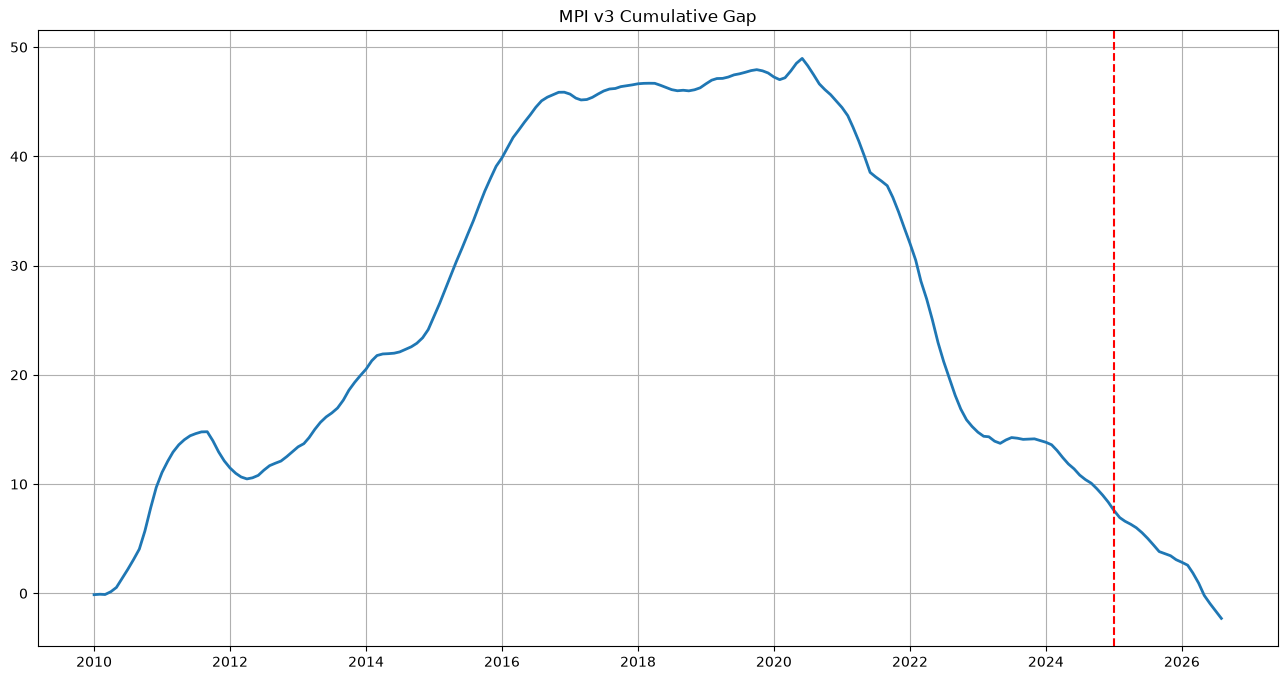

In [75]:
fig, ax = plt.subplots(
    figsize=(16,8)
)

ax.plot(
    compare_v3.index,
    compare_v3["cum_gap_v3"],
    linewidth=2
)

ax.axvline(
    pd.Timestamp("2025-01-01"),
    color="red",
    linestyle="--"
)

ax.grid(True)

ax.set_title(
    "MPI v3 Cumulative Gap"
)

output_path = (
    output_dir
    / f"MPI_v3_CumulativeGap_{today}.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print(
    "saved:",
    output_path
)

plt.show()

In [76]:
improvement = (
    (corr_v3 - corr_v2)
    / abs(corr_v2)
    * 100
)

print(
    f"Improvement = {improvement:.2f}%"
)

Improvement = 7.12%
